# SmartFood · Análisis exploratorio y selección de datos

Se analiza calidad de datos, distribución de interacciones y efecto del filtrado.

**Estado:** ejecución completa mediante el maestro el 6 de octubre de 2026; reejecutado el 7 de octubre de 2026 para validar rutas tras agrupar los reportes por etapa. Consulta el [registro de ejecución](../docs/ejecuciones.md).

**Cifras automáticas:** los bloques de interpretación se muestran como Markdown generado por celdas de código. Ejecuta todas las celdas en orden para actualizarlos.

El umbral seleccionado se aplica antes de intersectar usuarios y recetas. No garantiza ese mínimo en el resultado ni se ha demostrado óptimo.

Consulta la [revisión de conclusiones](../docs/revision_eda.md) y la [guía de ejecución](../docs/notebooks.md).


In [1]:
# Resolver la raíz del proyecto desde Jupyter o desde la carpeta del proyecto.
from pathlib import Path
import os
import sys

def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("smartfood")
if PROJECT_ROOT is None:
    raise RuntimeError("Inicia Jupyter desde la carpeta SmartFood o notebooks.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/intermediate", "data/processed", "data/output", "reports", "models"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

# Configuracion comun: registrar avisos para el resumen de alertas.
from smartfood.entorno_notebook import configurar_notebook
configurar_notebook()


## Paso 1 · Importar bibliotecas


In [2]:
# Importar librerías
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from smartfood.inspeccion import inspeccion_visual
from smartfood.inspeccion_md import inspeccion_visual_md
from smartfood.diagnostico import ejecutar_diagnostico
from smartfood.reporte import evaluar_viabilidad_modelo_general

from IPython.display import Markdown, display
from smartfood.anotaciones import calcular_metricas_eda, comentario_eda
comentarios_eda = {}


## ✅ Paso 2: Carga de datos

In [3]:
recipes = pd.read_parquet("data/intermediate/recipes_limpio.parquet")
print("Data shape: ", recipes.shape)
reviews = pd.read_parquet("data/intermediate/reviews_limpio.parquet")
print("Data shape: ", reviews.shape)
metricas_originales = calcular_metricas_eda(recipes, reviews)


Data shape:  (522517, 28)


Data shape:  (1401982, 8)


## Paso 3 · Exploración visual

Inspección de dimensiones, tipos, nulos, duplicados y distribuciones. Las listas requieren un tratamiento específico para calcular cardinalidad.


In [4]:
print("inspeccion_visual(reviews)")
inspeccion_visual(reviews)

inspeccion_visual(reviews)


In [5]:
print("inspeccion_visual(recipes)")
inspeccion_visual(recipes)

inspeccion_visual(recipes)


In [6]:
inspeccion_visual_md(reviews, nombre="reviews")
inspeccion_visual_md(recipes, nombre="recipes")

Archivo Markdown generado en: D:\portafolio\Analisis\Recommenders\SmartFood\reports\eda\reviews\inspeccion_reviews.md


Archivo Markdown generado en: D:\portafolio\Analisis\Recommenders\SmartFood\reports\eda\recipes\inspeccion_recipes.md


WindowsPath('reports/eda/recipes/inspeccion_recipes.md')

## Paso 4 · Calidad de datos y distribución de valoraciones

Las conclusiones deben considerar todos los resultados, incluidos los errores capturados por los diagnósticos.


📊 Diagnóstico de `recipes`
📌 ¿Cuántas recetas hay en total?
522517
------------------------------------------------------------
📌 ¿Qué columnas tienen más de 30% de valores nulos?


recipeyield         0.666143
aggregatedrating    0.484622
reviewcount         0.473648
recipeservings      0.350058
------------------------------------------------------------
📌 ¿Qué columnas tienen 5 o menos valores únicos?


⚠️ Error al ejecutar columnas_baja_cardinalidad: unhashable type: 'numpy.ndarray'
------------------------------------------------------------
📌 ¿Qué columnas tienen valores únicos por fila (como IDs)?
⚠️ Error al ejecutar columnas_muy_unicas: unhashable type: 'numpy.ndarray'
------------------------------------------------------------
📌 ¿Cómo se distribuyen las calorías?


count    522517.000000
mean        484.438580
std        1397.116649
min           0.000000
25%         174.200000
50%         317.100000
75%         529.100000
max      612854.600000
------------------------------------------------------------
📌 ¿Cómo se distribuyen los aggregatedrating?
count    269294.000000
mean          4.632014
std           0.641934
min           1.000000
25%           4.500000
50%           5.000000
75%           5.000000
max           5.000000
------------------------------------------------------------
📌 ¿Cuáles son las columnas tipo object?
name, authorname, cooktime, preptime, totaltime, description, images, recipecate
gory, keywords, recipeingredientquantities, recipeingredientparts, recipeyield, 
recipeinstructions
------------------------------------------------------------
📌 ¿Cuáles son las columnas numéricas?
recipeid, aggregatedrating, reviewcount, calories, fatcontent, saturatedfatconte
nt, cholesterolcontent, sodiumcontent, carbohydratecontent, fibe

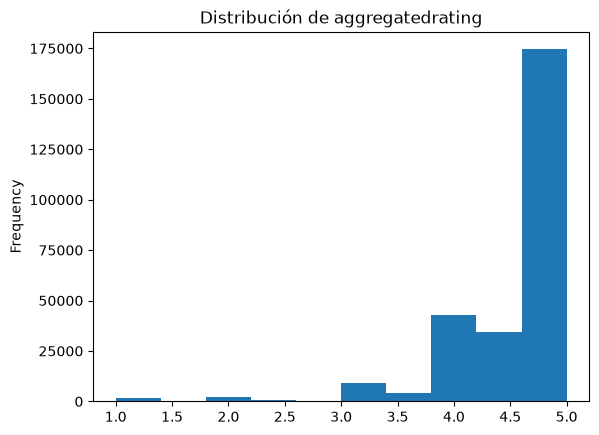

------------------------------------------------------------


In [7]:
# Definir diagnósticos para el dataset de recetas
diagnosticos_recipes = {
    "cantidad_total_recetas": {
        "pregunta": "¿Cuántas recetas hay en total?",
        "funcion": lambda recipes: recipes['recipeid'].nunique(),
        "mensaje_si_vacio": "✅ No hay recetas en el dataset."
    },
    "columnas_con_mas_de_30_por_ciento_nulos": {
        "pregunta": "¿Qué columnas tienen más de 30% de valores nulos?",
        "funcion": lambda recipes: recipes.isnull().mean().sort_values(ascending=False).loc[lambda x: x > 0.3],
        "mensaje_si_vacio": "✅ No hay columnas con más del 30% de valores nulos."
    },
    "columnas_baja_cardinalidad": {
        "pregunta": "¿Qué columnas tienen 5 o menos valores únicos?",
        "funcion": lambda recipes: recipes.nunique().sort_values().loc[lambda x: x <= 5],
        "mensaje_si_vacio": "✅ Todas las columnas tienen más de 5 valores únicos."
    },
    "columnas_muy_unicas": {
        "pregunta": "¿Qué columnas tienen valores únicos por fila (como IDs)?",
        "funcion": lambda recipes: recipes.nunique().sort_values(ascending=False).loc[lambda x: x >= len(recipes) * 0.95],
        "mensaje_si_vacio": "✅ No hay columnas que sean únicas en más del 95% de los registros."
    },
    "resumen_calorias": {
        "pregunta": "¿Cómo se distribuyen las calorías?",
        "funcion": lambda recipes: recipes['calories'].describe(),
        "mensaje_si_vacio": "✅ No hay calorías en el dataset."
    },
    "resumen_aggregatedrating": {
        "pregunta": "¿Cómo se distribuyen los aggregatedrating?",
        "funcion": lambda recipes: recipes['aggregatedrating'].dropna().describe(),
        "mensaje_si_vacio": "✅ No hay aggregatedrating en el dataset."
    },
    "columnas_tipo_object": {
        "pregunta": "¿Cuáles son las columnas tipo object?",
        "funcion": lambda recipes: recipes.select_dtypes(include='object').columns.tolist(),
        "mensaje_si_vacio": "✅ No hay columnas de tipo object."
    },
    "columnas_tipo_numerico": {
        "pregunta": "¿Cuáles son las columnas numéricas?",
        "funcion": lambda recipes: recipes.select_dtypes(include=['int64', 'float64']).columns.tolist(),
        "mensaje_si_vacio": "✅ No hay columnas numéricas."
    },
    "histograma_aggregatedrating": {
        "pregunta": "Histograma de aggregatedrating",
        "funcion": lambda recipes: recipes['aggregatedrating'].dropna().plot(kind='hist', bins=10, title='Distribución de aggregatedrating'),
        "mensaje_si_vacio": "✅ No hay aggregatedrating en el dataset."
    }
}

# usar la función ejecutar_diagnostico_recipes
diagnosticos_recipes_result = ejecutar_diagnostico(recipes, diagnosticos_recipes, nombre_dataset = "recipes")
diagnosticos_recipes_result

In [8]:
# Markdown generado a partir de los datos de esta ejecucion.
texto = comentario_eda("recetas", metricas_originales)
comentarios_eda["recetas"] = texto
display(Markdown(texto))


### Interpretación del catálogo de recetas

Hay **522.517 recetas distintas** en **522.517 filas**. Entre los **269.294 ratings agregados disponibles**, la mediana es **5,00**, la media **4,632** y la desviación estándar **0,642**.

Porcentaje de nulos: `aggregatedrating`: **48,46 %**; `reviewcount`: **47,36 %**; `recipeyield`: **66,61 %**; `recipeservings`: **35,01 %**.

Las calorías tienen mediana **317,10**, media **484,44** y máximo **612.854,6**. Los extremos requieren revisar unidades y procedencia.

Las cifras anteriores no validan cardinalidad ni redundancia de columnas con listas; revisa los errores del diagnóstico precedente. Seleccionar solo `int64/float64` tampoco incluye todos los tipos numéricos. El rating agregado difiere de una valoración individual y su uso requiere revisar la disponibilidad temporal.

📊 Diagnóstico de `reviews`
📌 ¿Cuántas reviews hay en total?
1401982
------------------------------------------------------------
📌 ¿Cuántos usuarios únicos hay?
271907
------------------------------------------------------------
📌 ¿Cuántas recetas diferentes fueron evaluadas?
271678
------------------------------------------------------------
📌 ¿Cómo se distribuyen los ratings?


count    1.401982e+06
mean     4.407951e+00
std      1.272012e+00
min      0.000000e+00
25%      4.000000e+00
50%      5.000000e+00
75%      5.000000e+00
max      5.000000e+00
------------------------------------------------------------
📌 ¿Qué valores únicos tiene la columna rating?
[5 4 2 0 1 3]
------------------------------------------------------------
📌 ¿Qué columnas tienen valores nulos?
✅ No hay columnas con valores nulos.
------------------------------------------------------------
📌 ¿Qué columnas tienen más del 95% de valores únicos?


reviewid         1401982
review           1387058
datesubmitted    1384268
datemodified     1384268
------------------------------------------------------------
📌 ¿Qué columnas tienen 5 o menos valores únicos?


✅ Todas las columnas tienen más de 5 valores únicos.
------------------------------------------------------------
📌 ¿Cuántos registros están 100% duplicados?


0
------------------------------------------------------------
📌 ¿Cuál es el nivel de esparsidad de la matriz usuario-receta?
0.9999810212511783
------------------------------------------------------------
📌 Histograma de ratings


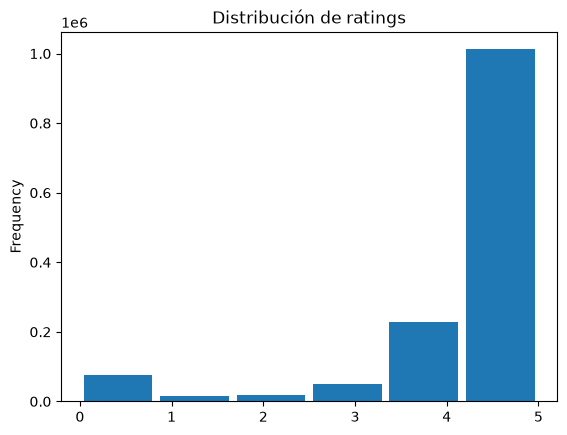

------------------------------------------------------------


In [9]:
# Definir diagnósticos para el dataset de reviews
diagnosticos_reviews = {
    "cantidad_total_reviews": {
        "pregunta": "¿Cuántas reviews hay en total?",
        "funcion": lambda df: len(df),
        "mensaje_si_vacio": "✅ No hay registros en el dataset."
    },
    "usuarios_unicos": {
        "pregunta": "¿Cuántos usuarios únicos hay?",
        "funcion": lambda df: df['authorid'].nunique(),
        "mensaje_si_vacio": "✅ No hay usuarios únicos."
    },
    "recetas_unicas": {
        "pregunta": "¿Cuántas recetas diferentes fueron evaluadas?",
        "funcion": lambda df: df['recipeid'].nunique(),
        "mensaje_si_vacio": "✅ No hay recetas únicas."
    },
    "distribucion_rating": {
        "pregunta": "¿Cómo se distribuyen los ratings?",
        "funcion": lambda df: df['rating'].describe(),
        "mensaje_si_vacio": "✅ No hay ratings."
    },
    "rating_valores_unicos": {
        "pregunta": "¿Qué valores únicos tiene la columna rating?",
        "funcion": lambda df: df['rating'].unique(),
        "mensaje_si_vacio": "❌ No se encontraron valores en la columna 'rating'."
    },
    "columnas_con_nulos": {
        "pregunta": "¿Qué columnas tienen valores nulos?",
        "funcion": lambda df: df.isnull().sum().loc[lambda x: x > 0],
        "mensaje_si_vacio": "✅ No hay columnas con valores nulos."
    },
    "columnas_muy_unicas": {
        "pregunta": "¿Qué columnas tienen más del 95% de valores únicos?",
        "funcion": lambda df: df.nunique().sort_values(ascending=False).loc[lambda x: x / len(df) > 0.95],
        "mensaje_si_vacio": "✅ No hay columnas con más del 95% de valores únicos."
    },
    "columnas_baja_cardinalidad": {
        "pregunta": "¿Qué columnas tienen 5 o menos valores únicos?",
        "funcion": lambda df: df.nunique().sort_values().loc[lambda x: x <= 5],
        "mensaje_si_vacio": "✅ Todas las columnas tienen más de 5 valores únicos."
    },
    "duplicados_exactos": {
        "pregunta": "¿Cuántos registros están 100% duplicados?",
        "funcion": lambda df: df.duplicated().sum(),
        "mensaje_si_vacio": "✅ No hay registros duplicados."
    },
    "nivel_esparsidad": {
        "pregunta": "¿Cuál es el nivel de esparsidad de la matriz usuario-receta?",
        "funcion": lambda df: 1 - (len(df) / (df['authorid'].nunique() * df['recipeid'].nunique())),
        "mensaje_si_vacio": "✅ No hay registros."
    },
    "histograma_rating": {
        "pregunta": "Histograma de ratings",
        "funcion": lambda df: df['rating'].plot(kind='hist', bins=6, rwidth=0.9, title="Distribución de ratings"),
        "mensaje_si_vacio": "✅ No hay registros."
    }
}


# usar la función ejecutar_diagnostico_reviews
diagnosticos_reviews_result = ejecutar_diagnostico(reviews, diagnosticos_reviews, nombre_dataset="reviews")
diagnosticos_reviews_result

In [10]:
# Markdown generado a partir de los datos de esta ejecucion.
texto = comentario_eda("reviews", metricas_originales)
comentarios_eda["reviews"] = texto
display(Markdown(texto))


### Interpretación de las reseñas

Hay **1.401.982 reseñas**, **271.907 usuarios** y **271.678 recetas evaluadas**. El **72,19 %** de los ratings es 5 y el **5,44 %** es 0.

La esparsidad es **99,9981 %**, calculada con **1.401.982 pares únicos**. Los ceros cuentan como interacciones registradas; excluirlos cambia la definición de observación.

Se detectan **0 filas adicionales con pares usuario–receta repetidos**, **0 valores nulos** en usuario, receta o rating y **19 pares** cuya receta no aparece en el catálogo. Estos controles no validan semánticamente todos los campos.

Debe definirse el significado de rating cero y comparar modelos con baselines. La esparsidad no demuestra que NMF sea adecuado; centrar ratings puede generar negativos incompatibles con NMF. Los ingredientes necesitan preparación para TF-IDF y los IDs recodificados requieren mapeos persistidos.

## ✅ Paso 5: Diagnóstico viabilidad del modelo

In [11]:
resultado_evaluacion_modelo = evaluar_viabilidad_modelo_general(
    df_interacciones=reviews,
    df_items=recipes,
    col_usuario="authorid",
    col_item="recipeid",
    col_rating="rating",
    features_relevantes=["calories", "aggregatedrating", "recipeingredientparts"]
)
print(resultado_evaluacion_modelo)

🔷 Evaluación para NMF
✅ Usuarios: 271907, Recetas: 271678 → OK
✅ Interacciones: 1401982 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.99998
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


In [12]:
# Markdown generado a partir de los datos de esta ejecucion.
texto = comentario_eda("viabilidad", metricas_originales)
comentarios_eda["viabilidad"] = texto
display(Markdown(texto))


### Alcance del diagnóstico de viabilidad

`evaluar_viabilidad_modelo_general` aplica umbrales heurísticos, no valida desempeño. «Varianza aceptable» solo comprueba si la clase dominante está por debajo del 90 %; «Target con más de dos clases» describe el rating original, aunque el SVM usa `rating >= 4`.

Una matriz densa float64 de los usuarios y recetas observados ocuparía **590,97 GB** (unidades decimales), sin copias ni objetos adicionales. Conviene evaluar estructuras dispersas y documentar el muestreo.

## Paso 6 · Historial de interacciones y comparación de filtros


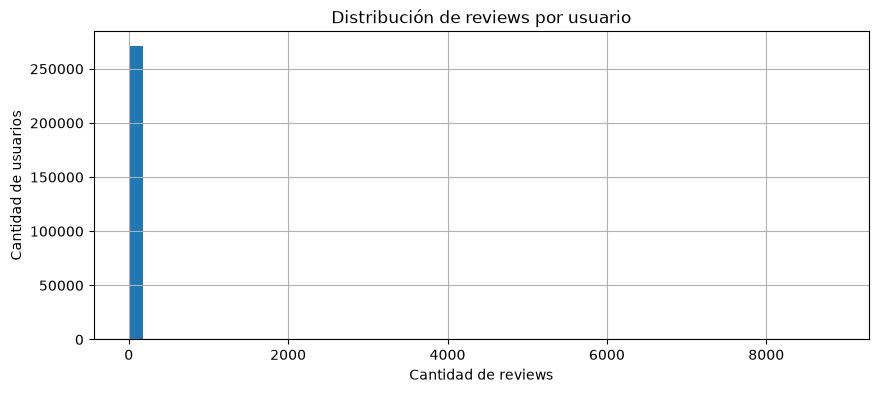

count    271907.000000
mean          5.156109
std          53.468238
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        8842.000000
Name: count, dtype: float64


In [13]:
# Paso 1: Ver la distribución de cantidad de reviews por usuario
reviews_por_usuario = reviews['authorid'].value_counts()
reviews_por_usuario.hist(bins=50, figsize=(10, 4))
plt.title("Distribución de reviews por usuario")
plt.xlabel("Cantidad de reviews")
plt.ylabel("Cantidad de usuarios")
plt.grid(True)
plt.show()

# Estadísticas útiles
print(reviews_por_usuario.describe())


In [14]:
# Markdown generado a partir de los datos de esta ejecucion.
texto = comentario_eda("historial_usuarios", metricas_originales)
comentarios_eda["historial_usuarios"] = texto
display(Markdown(texto))


### Historial de usuarios

Para **271.907 usuarios con pares registrados**, la mediana es **1,00**, el tercer cuartil **2,00**, la media **5,16**, la desviación estándar **53,47** y el máximo **8.842**. Se cuentan recetas distintas por usuario y usuarios distintos por receta.

El catálogo contiene **522.517 recetas distintas**; las recetas sin reseñas no participan en la distribución de historiales. Un historial escaso limita la personalización; no demuestra ruido ni justifica excluir entidades sin evaluar cobertura y cold start.

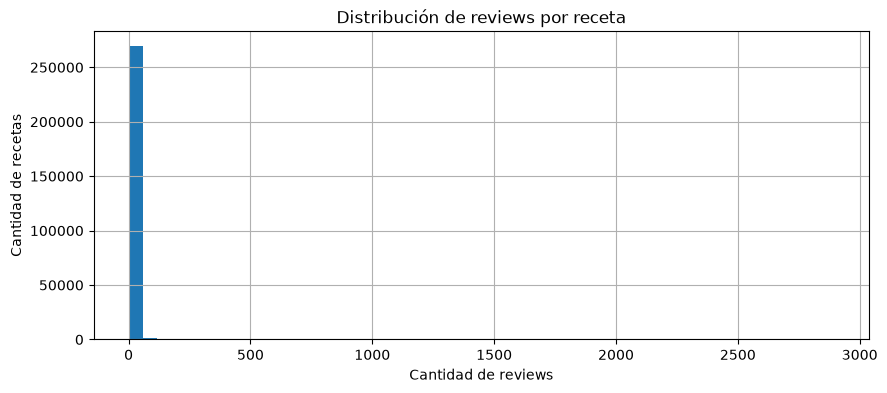

count    271678.000000
mean          5.160455
std          19.708589
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        2892.000000
Name: count, dtype: float64


In [15]:
# Paso 2: Ver distribución de cantidad de reviews por receta
reviews_por_receta = reviews['recipeid'].value_counts()
reviews_por_receta.hist(bins=50, figsize=(10, 4))
plt.title("Distribución de reviews por receta")
plt.xlabel("Cantidad de reviews")
plt.ylabel("Cantidad de recetas")
plt.grid(True)
plt.show()

# Estadísticas útiles
print(reviews_por_receta.describe())


In [16]:
# Markdown generado a partir de los datos de esta ejecucion.
texto = comentario_eda("historial_recetas", metricas_originales)
comentarios_eda["historial_recetas"] = texto
display(Markdown(texto))


### Historial de recetas

Para **271.678 recetas con pares registrados**, la mediana es **2,00**, el tercer cuartil **4,00**, la media **5,16**, la desviación estándar **19,71** y el máximo **2.892**. Se cuentan recetas distintas por usuario y usuarios distintos por receta.

El catálogo contiene **522.517 recetas distintas**; las recetas sin reseñas no participan en la distribución de historiales. Un historial escaso limita la personalización; no demuestra ruido ni justifica excluir entidades sin evaluar cobertura y cold start.

In [17]:
# Paso 3: Tabla resumen por distintos filtros
def resumen_filtros(min_reviews):
    resumen = []
    for k in min_reviews:
        usuarios = (reviews_por_usuario >= k).sum()
        recetas = (reviews_por_receta >= k).sum()
        interacciones = reviews[
            reviews['authorid'].isin(reviews_por_usuario[reviews_por_usuario >= k].index) &
            reviews['recipeid'].isin(reviews_por_receta[reviews_por_receta >= k].index)
        ]
        resumen.append({
            "min_reviews": k,
            "usuarios_filtrados": usuarios,
            "recetas_filtradas": recetas,
            "interacciones_restantes": len(interacciones)
        })
    return pd.DataFrame(resumen)

min_reviews = [1, 3, 5, 10, 15] + list(range(50, 301, 10))
print(resumen_filtros(min_reviews).set_index("min_reviews").to_markdown(index=True))


|   min_reviews |   usuarios_filtrados |   recetas_filtradas |   interacciones_restantes |
|--------------:|---------------------:|--------------------:|--------------------------:|
|             1 |               271907 |              271678 |                   1401982 |
|             3 |                45032 |              112729 |                    966384 |
|             5 |                27683 |               64828 |                    783379 |
|            10 |                15173 |               26647 |                    530589 |
|            15 |                10641 |               15389 |                    402535 |
|            50 |                 3427 |                2873 |                    138910 |
|            60 |                 2893 |                2207 |                    114513 |
|            70 |                 2484 |                1725 |                     94099 |
|            80 |                 2173 |                1438 |                     80146 |

### Comparación de umbrales

La tabla anterior cuenta usuarios y recetas que cumplen el umbral **antes de la intersección**. No son necesariamente los que permanecen en el resultado. El diagnóstico siguiente sí cuenta entidades presentes, pero continúa siendo heurístico y no determina un tamaño óptimo.


In [18]:
for num_usuarios in min_reviews:
    
    # Paso 1: Filtrar por conteos originales; el mínimo final no queda garantizado
    reviews_por_usuario = reviews['authorid'].value_counts()
    reviews_por_receta = reviews['recipeid'].value_counts()

    # Filtrar IDs válidos según criterio
    usuarios_validos = reviews_por_usuario[reviews_por_usuario >= num_usuarios].index
    recetas_validas = reviews_por_receta[reviews_por_receta >= num_usuarios].index

    # Filtrar el dataset de reviews
    reviews_filtrado = reviews[
        reviews['authorid'].isin(usuarios_validos) &
        reviews['recipeid'].isin(recetas_validas)
    ].copy()

    # Paso 2: Filtrar recipes según las recetas válidas
    recipes_filtrado = recipes[recipes['recipeid'].isin(recetas_validas)].copy()

    # Paso 3: Actualizar los IDs en el dataset de reviews
    reviews_filtrado['authorid'] = pd.Categorical(reviews_filtrado['authorid'], categories=usuarios_validos).codes
    reviews_filtrado['recipeid'] = pd.Categorical(reviews_filtrado['recipeid'], categories=recetas_validas).codes

    # Paso 4: Actualizar los IDs en el dataset de recipes
    recipes_filtrado['recipeid'] = pd.Categorical(recipes_filtrado['recipeid'], categories=recetas_validas).codes

    resultado_evaluacion_modelo_filtrado = evaluar_viabilidad_modelo_general(
        df_interacciones=reviews_filtrado,
        df_items=recipes_filtrado,
        col_usuario="authorid",
        col_item="recipeid",
        col_rating="rating",
        features_relevantes=["calories", "aggregatedrating", "recipeingredientparts"]
    )
    print(f"\n\nEvaluacion para usuarios y recetas con al menos: {num_usuarios} interacciones")
    print(resultado_evaluacion_modelo_filtrado)



Evaluacion para usuarios y recetas con al menos: 1 interacciones
🔷 Evaluación para NMF
✅ Usuarios: 271907, Recetas: 271678 → OK
✅ Interacciones: 1401982 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.99998
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM




Evaluacion para usuarios y recetas con al menos: 3 interacciones
🔷 Evaluación para NMF
✅ Usuarios: 44899, Recetas: 111767 → OK
✅ Interacciones: 966384 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.99981
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM




Evaluacion para usuarios y recetas con al menos: 5 interacciones
🔷 Evaluación para NMF
✅ Usuarios: 27626, Recetas: 64457 → OK
✅ Interacciones: 783379 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.99956
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 10 interacciones
🔷 Evaluación para NMF
✅ Usuarios: 15146, Recetas: 26553 → OK
✅ Interacciones: 530589 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.99868
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM




Evaluacion para usuarios y recetas con al menos: 15 interacciones
🔷 Evaluación para NMF
✅ Usuarios: 10633, Recetas: 15336 → OK
✅ Interacciones: 402535 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.99753
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 50 interacciones
🔷 Evaluación para NMF
✅ Usuarios: 3417, Recetas: 2870 → OK
✅ Interacciones: 138910 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.98584
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM




Evaluacion para usuarios y recetas con al menos: 60 interacciones
🔷 Evaluación para NMF
✅ Usuarios: 2882, Recetas: 2204 → OK
✅ Interacciones: 114513 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.98197
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 70 interacciones
🔷 Evaluación para NMF
✅ Usuarios: 2476, Recetas: 1721 → OK
✅ Interacciones: 94099 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.97792
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 80 interacciones
🔷 Evaluación para NMF
✅ Usuarios: 2163, Recetas: 1435 → OK
✅ Interacciones: 80146 → OK
✅ Varianza en ratings aceptable
📉 

...



Evaluacion para usuarios y recetas con al menos: 180 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 956, Recetas: 383 → Poca diversidad
✅ Interacciones: 23073 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.93698
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 190 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 907, Recetas: 350 → Poca diversidad
✅ Interacciones: 20952 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.93400
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 200 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 851, Recetas: 324 → Poca diversidad
✅ Interacciones: 18951 →



Evaluacion para usuarios y recetas con al menos: 210 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 809, Recetas: 290 → Poca diversidad
✅ Interacciones: 16918 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.92789
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 220 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 768, Recetas: 268 → Poca diversidad
✅ Interacciones: 15386 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.92525
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 230 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 739, Recetas: 248 → Poca diversidad
✅ Interacciones: 14313 →



Evaluacion para usuarios y recetas con al menos: 240 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 701, Recetas: 230 → Poca diversidad
✅ Interacciones: 13063 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.91898
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 250 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 679, Recetas: 216 → Poca diversidad
✅ Interacciones: 12155 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.91712
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 260 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 650, Recetas: 202 → Poca diversidad
✅ Interacciones: 11234 →



Evaluacion para usuarios y recetas con al menos: 270 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 617, Recetas: 190 → Poca diversidad
✅ Interacciones: 10343 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.91177
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 280 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 593, Recetas: 176 → Poca diversidad
✅ Interacciones: 9454 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.90942
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


Evaluacion para usuarios y recetas con al menos: 290 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 570, Recetas: 169 → Poca diversidad
✅ Interacciones: 8906 → O



Evaluacion para usuarios y recetas con al menos: 300 interacciones
🔷 Evaluación para NMF
⚠️ Usuarios: 549, Recetas: 157 → Poca diversidad
✅ Interacciones: 8164 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.90528
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


## Paso 7 · Inspección del subconjunto seleccionado


In [19]:
# Paso 1: Filtrar por conteos originales; el mínimo final no queda garantizado

# Conteo de reviews por usuario y por receta
reviews_por_usuario = reviews['authorid'].value_counts()
reviews_por_receta = reviews['recipeid'].value_counts()

num_usuarios = 270

# Filtrar IDs válidos según criterio
usuarios_validos = reviews_por_usuario[reviews_por_usuario >= num_usuarios].index
recetas_validas = reviews_por_receta[reviews_por_receta >= num_usuarios].index

# Filtrar el dataset de reviews
reviews_filtrado = reviews[
    reviews['authorid'].isin(usuarios_validos) &
    reviews['recipeid'].isin(recetas_validas)
].copy()

# Paso 2: Filtrar recipes según las recetas válidas
recipes_filtrado = recipes[recipes['recipeid'].isin(recetas_validas)].copy()

# Paso 3: Actualizar los IDs en el dataset de reviews
reviews_filtrado['authorid'] = pd.Categorical(reviews_filtrado['authorid'], categories=usuarios_validos).codes
reviews_filtrado['recipeid'] = pd.Categorical(reviews_filtrado['recipeid'], categories=recetas_validas).codes

# Paso 4: Actualizar los IDs en el dataset de recipes
recipes_filtrado['recipeid'] = pd.Categorical(recipes_filtrado['recipeid'], categories=recetas_validas).codes

metricas_filtradas = calcular_metricas_eda(recipes_filtrado, reviews_filtrado)


In [20]:
# Markdown generado a partir de los datos de esta ejecucion.
texto = comentario_eda("filtro", metricas_filtradas, originales=metricas_originales, umbral=num_usuarios)
comentarios_eda["filtro"] = texto
display(Markdown(texto))


### Elección exploratoria del umbral

Se aplica el umbral **270** a los conteos originales antes de intersectar usuarios y recetas. No se ha demostrado que optimice error o ranking.

El resultado contiene **617 usuarios**, **190 recetas del catálogo** (**190 con reseñas**) y **10.343 reseñas**. Conserva el **0,227 %** de los usuarios observados, el **0,0364 %** del catálogo y el **0,738 %** de las reseñas.

Los mínimos finales de interacciones distintas son **1 por usuario** y **1 por receta observada**. El umbral previo no garantiza ese mínimo en el resultado. Las recetas del catálogo sin interacciones quedan fuera de estos mínimos. La cobertura no acredita representatividad.

In [21]:
resultado_evaluacion_modelo_filtrado = evaluar_viabilidad_modelo_general(
    df_interacciones=reviews_filtrado,
    df_items=recipes_filtrado,
    col_usuario="authorid",
    col_item="recipeid",
    col_rating="rating",
    features_relevantes=["calories", "aggregatedrating", "recipeingredientparts"]
)
print(resultado_evaluacion_modelo_filtrado)


🔷 Evaluación para NMF
⚠️ Usuarios: 617, Recetas: 190 → Poca diversidad
✅ Interacciones: 10343 → OK
✅ Varianza en ratings aceptable
📉 Esparsidad: 0.91177
⚠️ Esparsidad muy alta

🔶 Evaluación para SVM
✅ Columna target tiene más de 2 clases
✅ Features disponibles: calories, aggregatedrating, recipeingredientparts
✅ Volumen de datos adecuado para SVM


In [22]:
# Paso 5: Mostrar resumen de los datasets filtrados
print("Dataset de reviews filtrado:")
inspeccion_visual(reviews_filtrado)


Dataset de reviews filtrado:


In [23]:
print("Dataset de recipes filtrado:")
inspeccion_visual(recipes_filtrado)

Dataset de recipes filtrado:


In [24]:
inspeccion_visual_md(reviews_filtrado, nombre="reviews_filtrado")
inspeccion_visual_md(recipes_filtrado, nombre="recipes_filtrado")


Archivo Markdown generado en: D:\portafolio\Analisis\Recommenders\SmartFood\reports\eda\reviews_filtrado\inspeccion_reviews_filtrado.md


Archivo Markdown generado en: D:\portafolio\Analisis\Recommenders\SmartFood\reports\eda\recipes_filtrado\inspeccion_recipes_filtrado.md


WindowsPath('reports/eda/recipes_filtrado/inspeccion_recipes_filtrado.md')

📊 Diagnóstico de `recipes_filtrados`
📌 ¿Cuántas recetas hay en total?
190
------------------------------------------------------------
📌 ¿Qué columnas tienen más de 30% de valores nulos?
recipeyield       0.673684
recipeservings    0.400000
------------------------------------------------------------
📌 ¿Qué columnas tienen 5 o menos valores únicos?
⚠️ Error al ejecutar columnas_baja_cardinalidad: unhashable type: 'numpy.ndarray'
------------------------------------------------------------
📌 ¿Qué columnas tienen valores únicos por fila (como IDs)?
⚠️ Error al ejecutar columnas_muy_unicas: unhashable type: 'numpy.ndarray'
------------------------------------------------------------
📌 ¿Cómo se distribuyen las calorías?
count     190.000000
mean      402.502632
std       348.333677
min         0.000000
25%       200.125000
50%       322.950000
75%       506.350000
max      3343.800000
------------------------------------------------------------
📌 ¿Cómo se distribuyen los aggregatedrating?


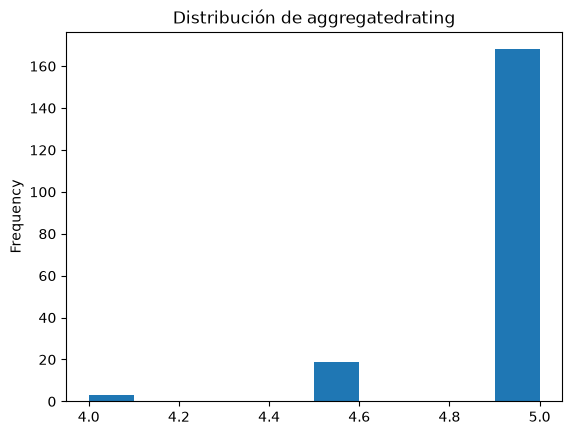

------------------------------------------------------------


In [25]:
# Paso 7: diagnosticos para los datasets filtrados
diagnosticos_recipes_filtrados_result = ejecutar_diagnostico(recipes_filtrado, diagnosticos_recipes, nombre_dataset = "recipes_filtrados")
diagnosticos_recipes_filtrados_result


In [26]:
# Markdown generado a partir de los datos de esta ejecucion.
texto = comentario_eda("recetas_filtradas", metricas_filtradas, originales=metricas_originales)
comentarios_eda["recetas_filtradas"] = texto
display(Markdown(texto))


### Interpretación de las recetas filtradas

Hay **190 recetas distintas** en **190 filas**. Entre los **190 ratings agregados disponibles**, la mediana es **5,00**, la media **4,934** y la desviación estándar **0,191**.

Porcentaje de nulos: `aggregatedrating`: **0,00 %**; `reviewcount`: **0,00 %**; `recipeyield`: **67,37 %**; `recipeservings`: **40,00 %**.

Las calorías tienen mediana **322,95**, media **402,50** y máximo **3.343,8**. Los extremos requieren revisar unidades y procedencia.

La desviación estándar de `aggregatedrating` pasa de **0,642 a 0,191**. El **88,42 %** del catálogo filtrado tiene rating agregado 5. Estos cambios describen la selección; no demuestran mejora predictiva ni corrección de errores.

Las cifras anteriores no validan cardinalidad ni redundancia de columnas con listas; revisa los errores del diagnóstico precedente. Seleccionar solo `int64/float64` tampoco incluye todos los tipos numéricos. El rating agregado difiere de una valoración individual y su uso requiere revisar la disponibilidad temporal.

In [27]:
# Correlaciones descriptivas del subconjunto seleccionado.
from smartfood.anotaciones import comentario_correlacion
for metodo in ("pearson", "spearman"):
    texto = comentario_correlacion(recipes_filtrado, "calories", "proteincontent", metodo=metodo)
    comentarios_eda["correlacion_" + metodo] = texto
    display(Markdown(texto))


### Correlación: `calories` y `proteincontent`

Método: **pearson**; **190 pares válidos**; **0 filas excluidas**.

El coeficiente es **0,713**: asociación **positiva, muy fuerte**, según los cortes descriptivos del proyecto para |r|: **0,10, 0,30, 0,50, 0,70**. Se clasifica con el coeficiente sin redondear; estos cortes son configurables, no universales. La magnitud no prueba significancia estadística, causalidad ni capacidad predictiva. Pearson describe asociación lineal y puede ser sensible a extremos; Spearman describe asociación monótona. Revisa también el gráfico, las unidades y la selección de datos.

### Correlación: `calories` y `proteincontent`

Método: **spearman**; **190 pares válidos**; **0 filas excluidas**.

El coeficiente es **0,797**: asociación **positiva, muy fuerte**, según los cortes descriptivos del proyecto para |r|: **0,10, 0,30, 0,50, 0,70**. Se clasifica con el coeficiente sin redondear; estos cortes son configurables, no universales. La magnitud no prueba significancia estadística, causalidad ni capacidad predictiva. Pearson describe asociación lineal y puede ser sensible a extremos; Spearman describe asociación monótona. Revisa también el gráfico, las unidades y la selección de datos.

📊 Diagnóstico de `reviews_filtrados`
📌 ¿Cuántas reviews hay en total?
10343
------------------------------------------------------------
📌 ¿Cuántos usuarios únicos hay?
617
------------------------------------------------------------
📌 ¿Cuántas recetas diferentes fueron evaluadas?
190
------------------------------------------------------------
📌 ¿Cómo se distribuyen los ratings?
count    10343.000000
mean         4.648555
std          0.839665
min          0.000000
25%          5.000000
50%          5.000000
75%          5.000000
max          5.000000
------------------------------------------------------------
📌 ¿Qué valores únicos tiene la columna rating?
[5 0 4 3 2 1]
------------------------------------------------------------
📌 ¿Qué columnas tienen valores nulos?
✅ No hay columnas con valores nulos.
------------------------------------------------------------
📌 ¿Qué columnas tienen más del 95% de valores únicos?
reviewid         10343
datemodified     10337
datesubmitted    10337

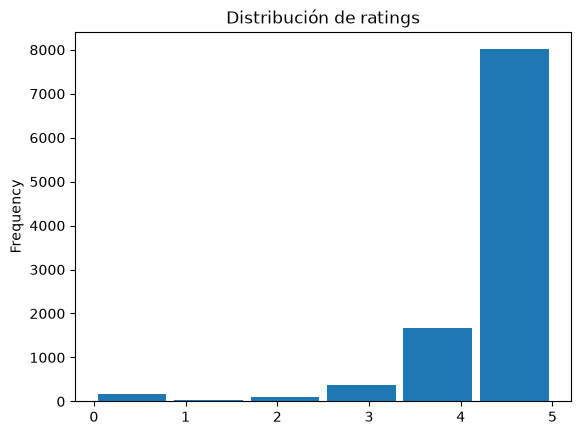

------------------------------------------------------------


In [28]:
diagnosticos_reviews_filtrados_result = ejecutar_diagnostico(reviews_filtrado, diagnosticos_reviews, nombre_dataset = "reviews_filtrados")
diagnosticos_reviews_filtrados_result

In [29]:
# Markdown generado a partir de los datos de esta ejecucion.
texto = comentario_eda("reviews_filtradas", metricas_filtradas, originales=metricas_originales)
comentarios_eda["reviews_filtradas"] = texto
display(Markdown(texto))


### Interpretación de las reseñas filtradas

Hay **10.343 reseñas**, **617 usuarios** y **190 recetas evaluadas**. El **77,43 %** de los ratings es 5 y el **1,62 %** es 0.

La esparsidad es **91,1772 %**, calculada con **10.343 pares únicos**. Los ceros cuentan como interacciones registradas; excluirlos cambia la definición de observación.

Se detectan **0 filas adicionales con pares usuario–receta repetidos**, **0 valores nulos** en usuario, receta o rating y **0 pares** cuya receta no aparece en el catálogo. Estos controles no validan semánticamente todos los campos.

Antes del filtro, los ratings 5 representaban **72,19 %** y los ceros **5,44 %**. El target `rating >= 4` sería positivo en el **93,61 %** del subconjunto. Ese porcentaje sería la accuracy de predecir siempre positivo sobre este conjunto, no una evaluación del SVM.

Debe definirse el significado de rating cero y comparar modelos con baselines. La esparsidad no demuestra que NMF sea adecuado; centrar ratings puede generar negativos incompatibles con NMF. Los ingredientes necesitan preparación para TF-IDF y los IDs recodificados requieren mapeos persistidos.

### Conclusión del análisis exploratorio

Los comentarios anteriores cuantifican el tamaño, la cobertura y la distribución de ratings de la ejecución actual. **No se ha demostrado reducción de ruido, mejora predictiva ni mantenimiento de representatividad.**

Antes del modelado deben completarse los controles fallidos de listas, preparar el contenido textual, definir el tratamiento de ceros y conservar los mapeos de IDs. Después se podrán comparar modelos y baselines mediante particiones y métricas apropiadas.

La [revisión del EDA](../docs/revision_eda.md) conserva las cifras verificadas de la ejecución anterior. Los comentarios automáticos describen los datos de esta ejecución; no actualizan esa revisión histórica.


## ✅ Paso 8: Guardar dataset filtrado

In [30]:
# Guardar en formato parquet para eficiencia
recipes_filtrado.to_parquet("data/processed/recipes_filtrado.parquet", index=False)
reviews_filtrado.to_parquet("data/processed/reviews_filtrado.parquet", index=False)

In [31]:
# Guardar las cifras y los comentarios de la ejecucion actual.
import json
reporte_eda = PROJECT_ROOT / "reports" / "eda"
reporte_eda.mkdir(parents=True, exist_ok=True)
(reporte_eda / "metricas_eda.json").write_text(
    json.dumps({"umbral": int(num_usuarios), "originales": metricas_originales,
                "filtradas": metricas_filtradas}, ensure_ascii=False, indent=2, allow_nan=False),
    encoding="utf-8",
)
(reporte_eda / "conclusiones_eda.md").write_text(
    "\n\n".join(comentarios_eda.values()) + "\n", encoding="utf-8"
)
print("Comentarios y cifras guardados en reports/eda/")


Comentarios y cifras guardados en reports/eda/


## Alertas de la ejecución

La tabla agrupa los avisos de Python y conserva su detalle original. Si una celda falla antes de llegar aquí, puedes ejecutar esta celda de resumen para consultar las alertas ya registradas. Los errores y los mensajes de diagnóstico impresos no se incluyen automáticamente.


In [32]:
from smartfood.entorno_notebook import mostrar_alertas
mostrar_alertas(PROJECT_ROOT / "reports" / "alertas" / "02_analisis_exploratorio.json")
from smartfood.informe import generar_informe
generar_informe(PROJECT_ROOT)


WindowsPath('D:/portafolio/Analisis/Recommenders/SmartFood/reports/informe_final/informe_final.md')